####  Распознавание предметов одежды Fashion MNIST
####  ОПТИМИЗИРОВАННАЯ ВЕРСИЯ ДЛЯ БЫСТРОГО ОБУЧЕНИЯ НА CPU

In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
%matplotlib inline

####  Фиксируем генератор случайных чисел

In [2]:
from numpy.random import seed
seed(2025)
from tensorflow.random import set_seed
set_seed(2025)

from tensorflow.keras.datasets import fashion_mnist

####  ЗАГРУЗКА И ПОДГОТОВКА ДАННЫХ

In [3]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

####  Названия классов

In [4]:
classes = ['футболка', 'брюки', 'свитер', 'платье', 'пальто', 
           'туфли', 'рубашка', 'кроссовки', 'сумка', 'ботинки']

print(f"Размер обучающей выборки: {x_train.shape}")
print(f"Размер тестовой выборки: {x_test.shape}")

Размер обучающей выборки: (60000, 28, 28)
Размер тестовой выборки: (10000, 28, 28)


####  Нормализация данных

In [5]:
x_train = x_train / 255.0
x_test = x_test / 255.0

#### Преобразование меток в категориальный формат

In [6]:
y_train_cat = utils.to_categorical(y_train, 10)
y_test_cat = utils.to_categorical(y_test, 10)

- TRAIN_MODEL_1 = True   # Быстрая полносвязная (~3-5 мин)
- TRAIN_MODEL_2 = True   # Легкая CNN (~5-10 мин)  
- TRAIN_MODEL_3 = True   # Оптимальная CNN (~10-15 мин) - ЛУЧШАЯ ТОЧНОСТЬ

In [7]:
TRAIN_MODEL_1 = True   
TRAIN_MODEL_2 = True    
TRAIN_MODEL_3 = True  

In [8]:
if TRAIN_MODEL_1:
 
    x_train_flat = x_train.reshape(60000, 784)
    x_test_flat = x_test.reshape(10000, 784)
    
    model1 = Sequential()
    model1.add(Input(shape=(784,)))
    model1.add(Dense(256, activation='relu'))
    model1.add(Dropout(0.3))
    model1.add(Dense(128, activation='relu'))
    model1.add(Dropout(0.3))
    model1.add(Dense(10, activation='softmax'))
    
    model1.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    print(model1.summary())
    
    start_time = time.time()
    history1 = model1.fit(
        x_train_flat, y_train_cat,
        batch_size=256, 
        epochs=20,
        validation_split=0.2,
        verbose=1,
        callbacks=[EarlyStopping(patience=3, restore_best_weights=True)]
    )
    train_time1 = time.time() - start_time
    
    score1 = model1.evaluate(x_test_flat, y_test_cat, verbose=0)
    print(f"\n Точность на тестовых данных: {score1[1]:.4f}")
    print(f" Время обучения: {train_time1/60:.1f} мин")
else:
    print("\n Модель 1 пропущена")
    score1 = [0, 0]
    history1 = None
    train_time1 = 0

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7458 - loss: 0.7192 - val_accuracy: 0.8382 - val_loss: 0.4477
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8358 - loss: 0.4628 - val_accuracy: 0.8577 - val_loss: 0.3956
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8520 - loss: 0.4132 - val_accuracy: 0.8637 - val_loss: 0.3850
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8609 - loss: 0.3842 - val_accuracy: 0.8738 - val_loss: 0.3531
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8673 - loss: 0.3632 - val_accuracy: 0.8774 - val_loss: 0.3462
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8741 - loss: 0.3478 - val_accuracy: 0.8799 - val_loss: 0.3370
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8761 - loss: 0.3374 - val_accuracy: 0.8809 - val_loss: 0.3322
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8783 - loss: 0.3296 - val_accurac

In [9]:
if TRAIN_MODEL_2:
    x_train_cnn = x_train.reshape(60000, 28, 28, 1)
    x_test_cnn = x_test.reshape(10000, 28, 28, 1)
    
    model2 = Sequential()
    model2.add(Input(shape=(28, 28, 1)))
    model2.add(Conv2D(32, (3, 3), activation='relu'))
    model2.add(MaxPooling2D((2, 2)))
    model2.add(Dropout(0.25))
    
    model2.add(Conv2D(64, (3, 3), activation='relu'))
    model2.add(MaxPooling2D((2, 2)))
    model2.add(Dropout(0.25))
    
    model2.add(Flatten())
    model2.add(Dense(128, activation='relu'))
    model2.add(Dropout(0.4))
    model2.add(Dense(10, activation='softmax'))
    
    model2.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    print(model2.summary())
    
    start_time = time.time()
    history2 = model2.fit(
        x_train_cnn, y_train_cat,
        batch_size=128,
        epochs=20,
        validation_split=0.2,
        verbose=1,
        callbacks=[EarlyStopping(patience=4, restore_best_weights=True)]
    )
    train_time2 = time.time() - start_time
    
    score2 = model2.evaluate(x_test_cnn, y_test_cat, verbose=0)
    print(f"\n Точность на тестовых данных: {score2[1]:.4f}")
    print(f" Время обучения: {train_time2/60:.1f} мин")
else:
    print("\n Модель 2 пропущена")
    score2 = [0, 0]
    history2 = None
    train_time2 = 0

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.7261 - loss: 0.7461 - val_accuracy: 0.8330 - val_loss: 0.4704
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8263 - loss: 0.4787 - val_accuracy: 0.8645 - val_loss: 0.3823
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8486 - loss: 0.4176 - val_accuracy: 0.8748 - val_loss: 0.3410
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8594 - loss: 0.3850 - val_accuracy: 0.8821 - val_loss: 0.3232
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8680 - loss: 0.3613 - val_accuracy: 0.8901 - val_loss: 0.2977
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8758 - loss: 0.3417 - val_accuracy: 0.8931 - val_loss: 0.2897
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8807 - loss: 0.3243 - val_accuracy: 0.8954 - val_loss: 0.2799
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8852 - loss: 0.3116 - val

In [10]:
if TRAIN_MODEL_3:
    
    if not TRAIN_MODEL_2:
        x_train_cnn = x_train.reshape(60000, 28, 28, 1)
        x_test_cnn = x_test.reshape(10000, 28, 28, 1)
    
    model3 = Sequential()
    model3.add(Input(shape=(28, 28, 1)))
    model3.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
    model3.add(BatchNormalization())
    model3.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
    model3.add(MaxPooling2D((2, 2)))
    model3.add(Dropout(0.25))
    
    model3.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model3.add(BatchNormalization())
    model3.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model3.add(MaxPooling2D((2, 2)))
    model3.add(Dropout(0.25))
    
    model3.add(Flatten())
    model3.add(Dense(256, activation='relu'))
    model3.add(BatchNormalization())
    model3.add(Dropout(0.5))
    model3.add(Dense(10, activation='softmax'))
    
    model3.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    print(model3.summary())
    
    start_time = time.time()
    history3 = model3.fit(
        x_train_cnn, y_train_cat,
        batch_size=128,
        epochs=25,  
        validation_split=0.2,
        verbose=1,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)]
    )
    train_time3 = time.time() - start_time
    
    score3 = model3.evaluate(x_test_cnn, y_test_cat, verbose=0)
    print(f"\n Точность на тестовых данных: {score3[1]:.4f}")
    print(f" Время обучения: {train_time3/60:.1f} мин")
else:
    print("\n Модель 3 пропущена")
    score3 = [0, 0]
    history3 = None
    train_time3 = 0

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 256)                 │         803,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 872,042 (3.33 MB)

 Trainable params: 871,338 (3.32 MB)

 Non-trainable params: 704 (2.75 KB)

None
Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 95ms/step - accuracy: 0.8173 - loss: 0.5248 - val_accuracy: 0.3644 - val_loss: 1.8462
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 35s 92ms/step - accuracy: 0.8827 - loss: 0.3300 - val_accuracy: 0.8783 - val_loss: 0.3292
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 33s 87ms/step - accuracy: 0.8990 - loss: 0.2859 - val_accuracy: 0.9043 - val_loss: 0.2597
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 87ms/step - accuracy: 0.9050 - loss: 0.2632 - val_accuracy: 0.9169 - val_loss: 0.2310
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 34s 90ms/step - accuracy: 0.9134 - loss: 0.2406 - val_accuracy: 0.9118 - val_loss: 0.2345
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 33s 87ms/step - accuracy: 0.9190 - loss: 0.2261 - val_accuracy: 0.9245 - val_loss: 0.2075
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 84ms/step - accuracy: 0.9241 - loss: 0.2126 - val_accuracy: 0.9251 - val_loss: 0.2061
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 84ms/step - accuracy: 0.9271 - loss: 0.20

#### СРАВНЕНИЕ РЕЗУЛЬТАТОВ

In [11]:
trained_models = []
if TRAIN_MODEL_1:
    trained_models.append(('Полносвязная', score1[1], train_time1/60))
if TRAIN_MODEL_2:
    trained_models.append(('CNN легкая', score2[1], train_time2/60))
if TRAIN_MODEL_3:
    trained_models.append(('CNN оптимальная', score3[1], train_time3/60))

if trained_models:
    results = pd.DataFrame(trained_models, columns=['Модель', 'Точность', 'Время (мин)'])
    print(results.to_string(index=False))
    
    best_acc = max(model[1] for model in trained_models)
    if best_acc >= 0.9:
        print(f"\n ЦЕЛЬ ДОСТИГНУТА! Лучшая точность: {best_acc:.4f}")
    else:
        print(f"\n Лучшая точность: {best_acc:.4f}. Попробуйте обучить дольше.")
else:
    print("Ни одна модель не была обучена!")

         Модель  Точность  Время (мин)
   Полносвязная    0.8852     0.276425
     CNN легкая    0.9121     2.257445
CNN оптимальная    0.9289    12.021041

 ЦЕЛЬ ДОСТИГНУТА! Лучшая точность: 0.9289


#### Найти лучшую модель

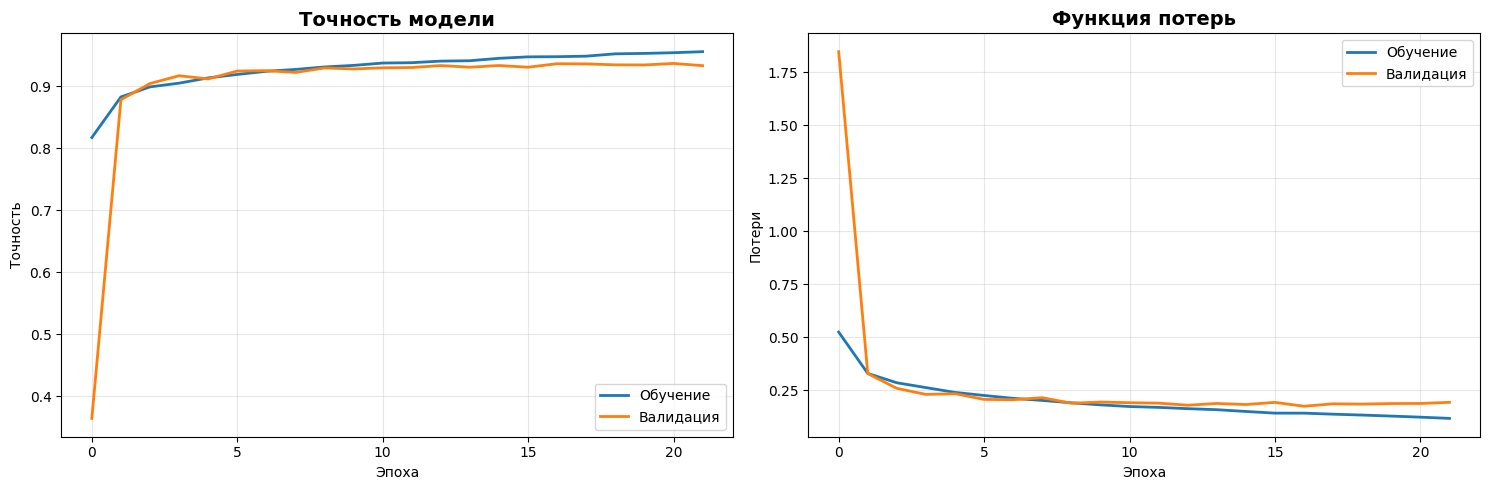

In [12]:
if trained_models:
    histories = []
    if TRAIN_MODEL_1 and history1: histories.append(history1)
    if TRAIN_MODEL_2 and history2: histories.append(history2)
    if TRAIN_MODEL_3 and history3: histories.append(history3)
    
    if histories:
        accuracies = [score1[1] if TRAIN_MODEL_1 else 0, 
                      score2[1] if TRAIN_MODEL_2 else 0,
                      score3[1] if TRAIN_MODEL_3 else 0]
        best_idx = np.argmax(accuracies)
        best_history = histories[min(best_idx, len(histories)-1)]
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        
        ax1.plot(best_history.history['accuracy'], label='Обучение', linewidth=2)
        ax1.plot(best_history.history['val_accuracy'], label='Валидация', linewidth=2)
        ax1.set_title('Точность модели', fontsize=14, fontweight='bold')
        ax1.set_xlabel('Эпоха')
        ax1.set_ylabel('Точность')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        ax2.plot(best_history.history['loss'], label='Обучение', linewidth=2)
        ax2.plot(best_history.history['val_loss'], label='Валидация', linewidth=2)
        ax2.set_title('Функция потерь', fontsize=14, fontweight='bold')
        ax2.set_xlabel('Эпоха')
        ax2.set_ylabel('Потери')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()

#### Выбираем лучшую модель


 ПРИМЕРЫ ПРЕДСКАЗАНИЙ ЛУЧШЕЙ МОДЕЛИ


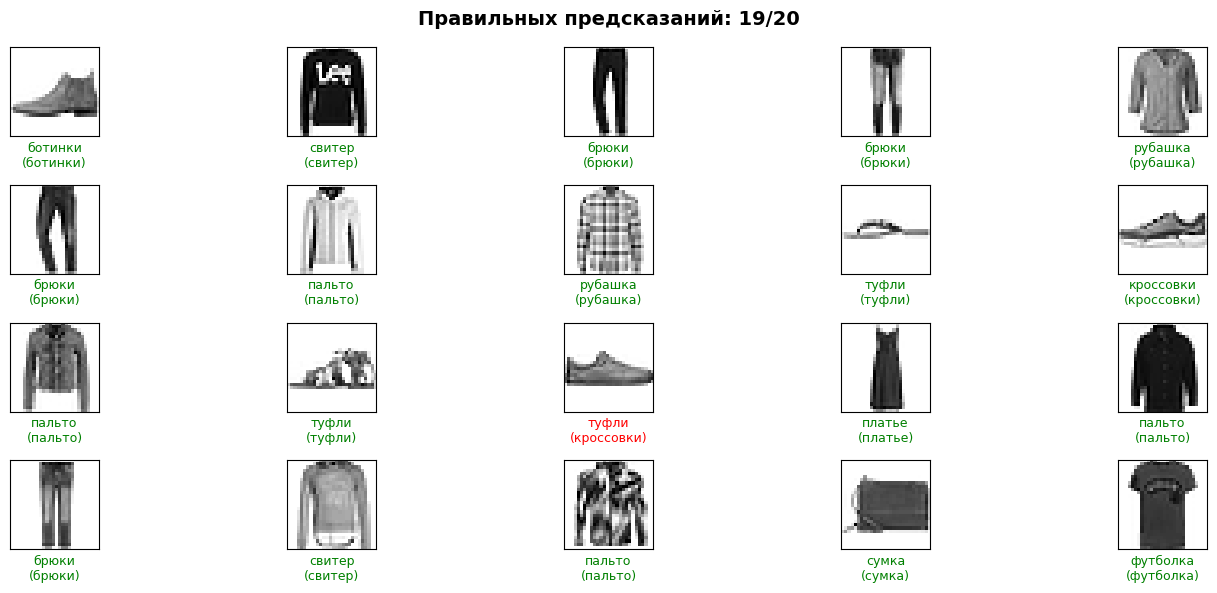

In [13]:
if trained_models:
    print("\n" + "="*70)
    print(" ПРИМЕРЫ ПРЕДСКАЗАНИЙ ЛУЧШЕЙ МОДЕЛИ")
    print("="*70)
    

    models_list = []
    test_data_list = []
    if TRAIN_MODEL_1:
        models_list.append(model1)
        test_data_list.append(x_test_flat)
    if TRAIN_MODEL_2:
        models_list.append(model2)
        test_data_list.append(x_test_cnn)
    if TRAIN_MODEL_3:
        models_list.append(model3)
        test_data_list.append(x_test_cnn)
    
    accuracies = [score1[1] if TRAIN_MODEL_1 else 0,
                  score2[1] if TRAIN_MODEL_2 else 0,
                  score3[1] if TRAIN_MODEL_3 else 0]
    
    best_model_idx = np.argmax(accuracies)
    trained_idx = sum([TRAIN_MODEL_1, TRAIN_MODEL_2][:best_model_idx+1]) - 1
    
    best_model = models_list[trained_idx]
    test_data = test_data_list[trained_idx]
    
    predictions = best_model.predict(test_data[:20], verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)
    
    plt.figure(figsize=(15, 6))
    correct = 0
    for i in range(20):
        plt.subplot(4, 5, i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(x_test[i], cmap=plt.cm.binary)
        
        predicted_label = classes[predicted_classes[i]]
        true_label = classes[y_test[i]]
        
        if predicted_classes[i] == y_test[i]:
            color = 'green'
            correct += 1
        else:
            color = 'red'
        
        plt.xlabel(f'{predicted_label}\n({true_label})', color=color, fontsize=9)
    
    plt.suptitle(f'Правильных предсказаний: {correct}/20', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()